## 1. Imports

In [ ]:
from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt




## 2. Path

In [11]:
PROJECT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

SPLIT_DIR = PROJECT_DIR / "splits"
MODEL_READY_DIR = PROJECT_DIR / "model_ready_no_dr"

MODEL_READY_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR = MODEL_READY_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Split directory:", SPLIT_DIR)
print("Model-ready output directory:", MODEL_READY_DIR)

Split directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits
Model-ready output directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr


In [13]:
train_no_dr_imputed = pd.read_csv(MODEL_READY_DIR / "train_no_dr_imputed.csv", low_memory=False)
print("Loaded:", train_no_dr_imputed.shape)
print("Labels:", train_no_dr_imputed["dataset_label"].value_counts().to_dict())

Loaded: (694549, 14)
Labels: {'normal': 497250, 'abnormal': 197299}


## 3. Loading the data splits created from EDA

In [3]:
train_path = SPLIT_DIR / "train_model_ready_selected_features.csv"
val_path = SPLIT_DIR / "val_model_ready_selected_features.csv"
test_path = SPLIT_DIR / "test_model_ready_selected_features.csv"

for path in [train_path, val_path, test_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

train_df = pd.read_csv(train_path, low_memory=False)
val_df = pd.read_csv(val_path, low_memory=False)
test_df = pd.read_csv(test_path, low_memory=False)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

Train shape: (694549, 19)
Validation shape: (138749, 19)
Test shape: (138524, 19)

Train columns:
['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'energy_increment_wh', 'power_w', 'time_s', 'target_energy_next_60s_wh']


## 4. feature colomn and target colomn 

In [4]:
target_col = "target_energy_next_60s_wh"

required_cols = ["log_id", "dataset_label", target_col]

for col in required_cols:
    if col not in train_df.columns:
        raise ValueError(f"Required column missing from train_df: {col}")

non_feature_cols = [
    "log_id",
    "dataset_label",
    target_col
]

feature_cols = [
    col for col in train_df.columns
    if col not in non_feature_cols
    and pd.api.types.is_numeric_dtype(train_df[col])
]

print("Feature count before duplicate removal:", len(feature_cols))
print(feature_cols)

Feature count before duplicate removal: 16
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'energy_increment_wh', 'power_w', 'time_s']


## 5.  duplicate feature removal  
because power_w already captures the same energy-use signal at 10 Hz

In [5]:
if "power_w" in feature_cols and "energy_increment_wh" in feature_cols:
    feature_cols.remove("energy_increment_wh")
    print("Removed energy_increment_wh .")

print("Final feature count:", len(feature_cols))
print(feature_cols)

Removed energy_increment_wh .
Final feature count: 15
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


## 5. Flight overlap check

In [6]:
train_ids = set(train_df["log_id"].astype(str).unique())
val_ids = set(val_df["log_id"].astype(str).unique())
test_ids = set(test_df["log_id"].astype(str).unique())

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("No flight-level leakage found.")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
No flight-level leakage found.


## 6. Missing-value check before imputation

In [7]:
missing_report = pd.DataFrame({
    "feature": feature_cols,
    "train_missing_%": train_df[feature_cols].isna().mean().values * 100,
    "val_missing_%": val_df[feature_cols].isna().mean().values * 100,
    "test_missing_%": test_df[feature_cols].isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(missing_report)

missing_report.to_csv(
    MODEL_READY_DIR / "missing_value_report_before_structural_removal_no_dr.csv",
    index=False
)

,feature,train_missing_%,val_missing_%,test_missing_%
6,battery_status__voltage_cell_v[0],76.07685,75.316579,70.920563
7,battery_status__voltage_cell_v[1],76.07685,75.316579,70.920563
8,battery_status__voltage_cell_v[2],76.07685,75.316579,70.920563
9,battery_status__voltage_cell_v[3],76.07685,75.316579,70.920563
0,battery_status__cell_count,0.00000,0.000000,0.000000
1,battery_status__current_a,0.00000,0.000000,0.000000
2,battery_status__current_filtered_a,0.00000,0.000000,0.000000
3,battery_status__discharged_mah,0.00000,0.000000,0.000000
4,battery_status__remaining,0.00000,0.000000,0.000000
5,battery_status__scale,0.00000,0.000000,0.000000


In [8]:

def find_feature_and_flight_with_missing(df, candidate_cols):
    for col in candidate_cols:
        flight_stats = (
            df.groupby("log_id")[col]
              .agg(
                  total_count="size",
                  missing_count=lambda x: x.isna().sum(),
                  observed_count=lambda x: x.notna().sum()
              )
        )

        mixed_flights = flight_stats[
            (flight_stats["missing_count"] > 0) &
            (flight_stats["observed_count"] > 0)
        ]

        if not mixed_flights.empty:
            return col, mixed_flights.index[0]

    return None, None


plot_feature, plot_flight_id = find_feature_and_flight_with_missing(
    train_df,
    feature_cols
)

print("Selected feature for plot:", plot_feature)
print("Selected flight:", plot_flight_id)

if plot_feature is not None:
    plot_before = (
        train_df[train_df["log_id"] == plot_flight_id]
        .sort_values("time_s")
        .copy()
    )

    plt.figure(figsize=(12, 4))
    plt.plot(
        plot_before["time_s"],
        plot_before[plot_feature],
        label="Before imputation"
    )

    missing_points = plot_before[plot_before[plot_feature].isna()]

    if plot_before[plot_feature].notna().any():
        y_marker = plot_before[plot_feature].min()
        plt.scatter(
            missing_points["time_s"],
            [y_marker] * len(missing_points),
            marker="x",
            label="Missing positions"
        )

    plt.title(f"Before Imputation: {plot_feature}")
    plt.xlabel("Time (s)")
    plt.ylabel(plot_feature)
    plt.legend()
    plt.show()
else:
    print("No mixed missing pattern found. Missingness may be structural rather than small time gaps.")

Selected feature for plot: None
Selected flight: None
No mixed missing pattern found. Missingness may be structural rather than small time gaps.


## 7. Time-series flow plot for one representative flight


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#important telemetry variables to visualise
timeseries_features = [
    "battery_status__voltage_v",
    "battery_status__current_a",
    "power_w",
    "cumulative_energy_wh",
    "target_energy_next_60s_wh"
]

#Keeping only columns that exist in the dataset
timeseries_features = [col for col in timeseries_features if col in train_df.columns]

print("Features selected for time-series plot:")
print(timeseries_features)

#to Select one normal flight with enough rows
normal_flights = (
    train_df[train_df["dataset_label"] == "normal"]
    .groupby("log_id")
    .size()
    .sort_values(ascending=False)
)

selected_flight_id = normal_flights.index[0]

flight_plot_df = (
    train_df[train_df["log_id"] == selected_flight_id]
    .sort_values("time_s")
    .copy()
)

print("Selected flight:", selected_flight_id)
print("Rows in selected flight:", flight_plot_df.shape[0])
print("Time range:", flight_plot_df["time_s"].min(), "to", flight_plot_df["time_s"].max(), "seconds")

Features selected for time-series plot:
['battery_status__voltage_v', 'battery_status__current_a', 'power_w', 'cumulative_energy_wh', 'target_energy_next_60s_wh']
Selected flight: 42b57f46-f2fe-45a4-8a31-928db553fb28
Rows in selected flight: 23914
Time range: 0.0 to 2391.3 seconds


## 8. Normalised time-series flow plot

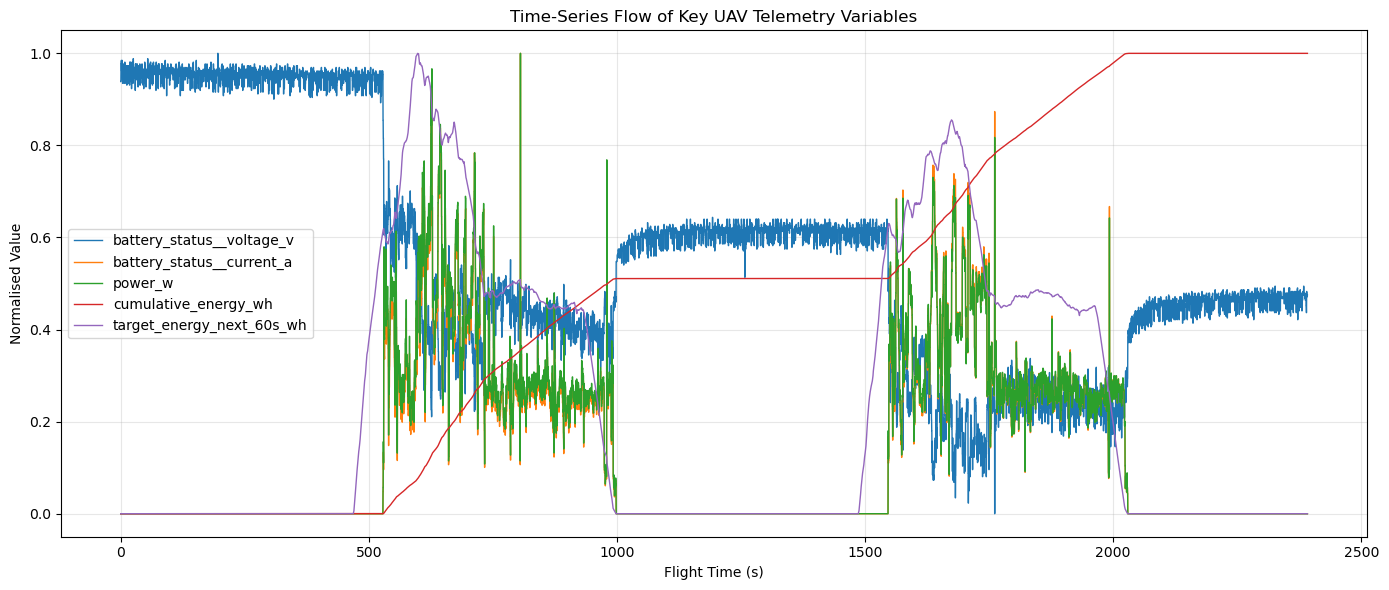

In [ ]:

#Normalisation is only for visualisation because all variables have different units.

plot_df = flight_plot_df[["time_s"] + timeseries_features].copy()

normalised_plot_df = plot_df.copy()

for col in timeseries_features:
    col_min = normalised_plot_df[col].min()
    col_max = normalised_plot_df[col].max()
    
    if col_max != col_min:
        normalised_plot_df[col] = (
            normalised_plot_df[col] - col_min
        ) / (col_max - col_min)
    else:
        normalised_plot_df[col] = 0

plt.figure(figsize=(14, 6))

for col in timeseries_features:
    plt.plot(
        normalised_plot_df["time_s"],
        normalised_plot_df[col],
        label=col,
        linewidth=1
    )

plt.title("Time-Series Flow of Key UAV Telemetry Variables")
plt.xlabel("Flight Time (s)")
plt.ylabel("Normalised Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Individual time-series plots with actual units

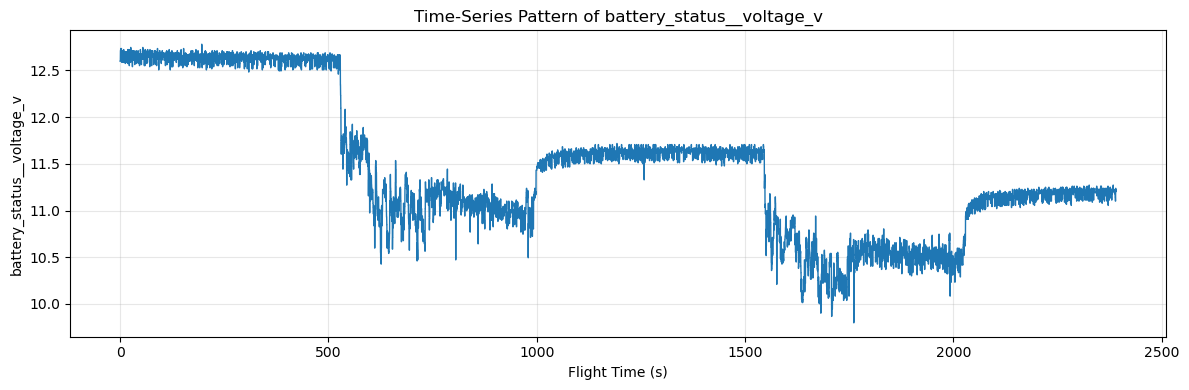

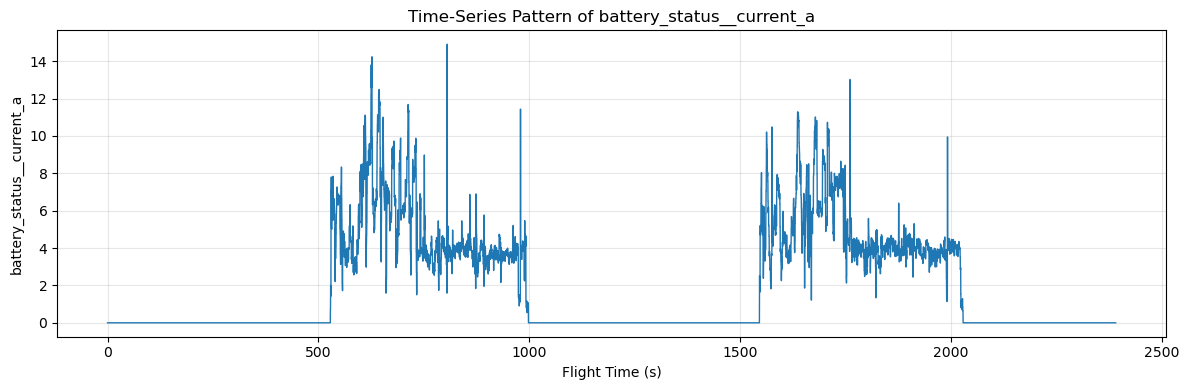

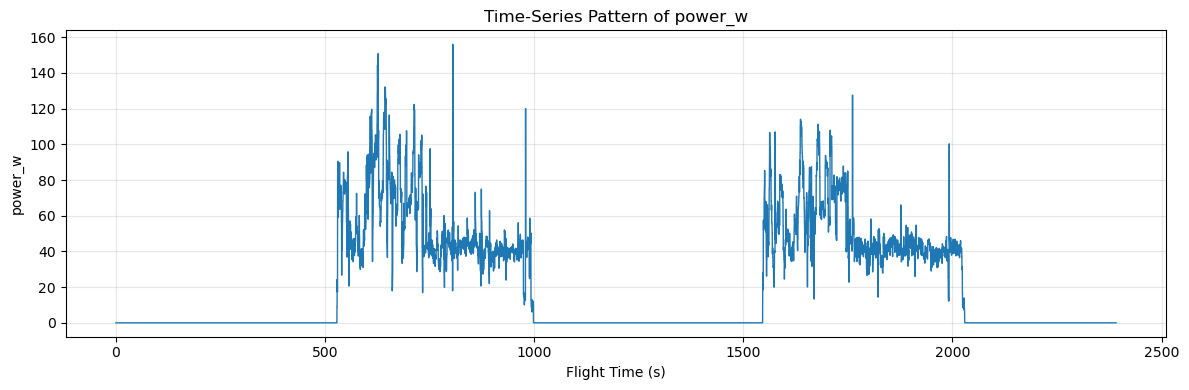

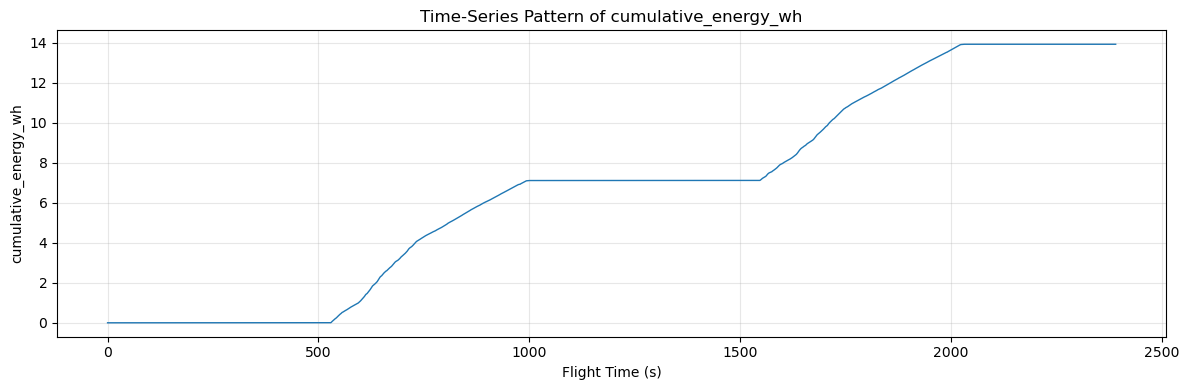

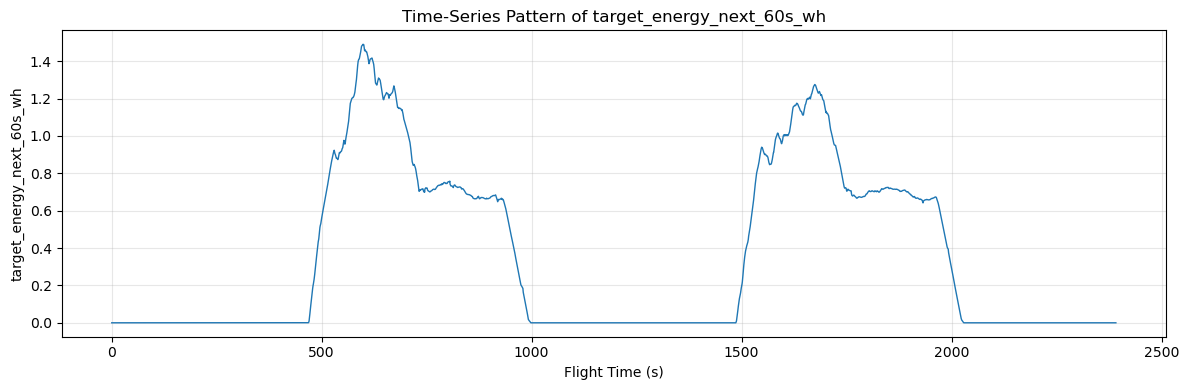

In [ ]:


for col in timeseries_features:
    plt.figure(figsize=(12, 4))
    
    plt.plot(
        flight_plot_df["time_s"],
        flight_plot_df[col],
        linewidth=1
    )
    
    plt.title(f"Time-Series Pattern of {col}")
    plt.xlabel("Flight Time (s)")
    plt.ylabel(col)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 10. Zoomed time-series flow plot for active flight section

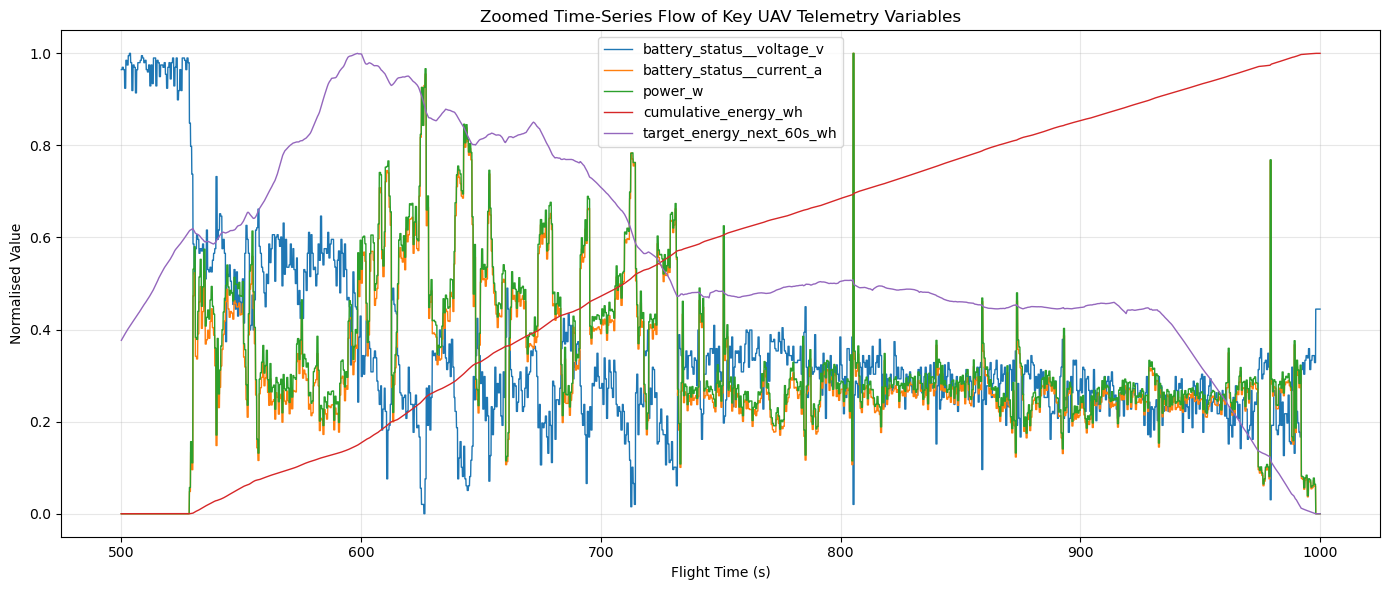

In [ ]:


START_TIME = 500
END_TIME = 1000

zoom_df = flight_plot_df[
    (flight_plot_df["time_s"] >= START_TIME) &
    (flight_plot_df["time_s"] <= END_TIME)
].copy()

plot_df = zoom_df[["time_s"] + timeseries_features].copy()
normalised_zoom_df = plot_df.copy()

for col in timeseries_features:
    col_min = normalised_zoom_df[col].min()
    col_max = normalised_zoom_df[col].max()
    
    if col_max != col_min:
        normalised_zoom_df[col] = (
            normalised_zoom_df[col] - col_min
        ) / (col_max - col_min)
    else:
        normalised_zoom_df[col] = 0

plt.figure(figsize=(14, 6))

for col in timeseries_features:
    plt.plot(
        normalised_zoom_df["time_s"],
        normalised_zoom_df[col],
        label=col,
        linewidth=1
    )

plt.title("Zoomed Time-Series Flow of Key UAV Telemetry Variables")
plt.xlabel("Flight Time (s)")
plt.ylabel("Normalised Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11.  structural missingness across flights

In [ ]:

cell_voltage_cols = [
    "battery_status__voltage_cell_v[0]",
    "battery_status__voltage_cell_v[1]",
    "battery_status__voltage_cell_v[2]",
    "battery_status__voltage_cell_v[3]"
]

structural_report = []

for col in cell_voltage_cols:
    if col in train_df.columns:
        per_flight = (
            train_df.groupby("log_id")[col]
            .agg(
                total_rows="size",
                missing_rows=lambda x: x.isna().sum(),
                observed_rows=lambda x: x.notna().sum()
            )
        )

        structural_report.append({
            "feature": col,
            "fully_missing_flights": ((per_flight["missing_rows"] > 0) & (per_flight["observed_rows"] == 0)).sum(),
            "partially_missing_flights": ((per_flight["missing_rows"] > 0) & (per_flight["observed_rows"] > 0)).sum(),
            "fully_observed_flights": ((per_flight["missing_rows"] == 0) & (per_flight["observed_rows"] > 0)).sum(),
            "overall_missing_%": train_df[col].isna().mean() * 100
        })

structural_report = pd.DataFrame(structural_report)
display(structural_report)

,feature,fully_missing_flights,partially_missing_flights,fully_observed_flights,overall_missing_%
0,battery_status__voltage_cell_v[0],92,0,25,76.07685
1,battery_status__voltage_cell_v[1],92,0,25,76.07685
2,battery_status__voltage_cell_v[2],92,0,25,76.07685
3,battery_status__voltage_cell_v[3],92,0,25,76.07685


## 12. Remove structurally missing cell-voltage columns before creating X and y

In [14]:


structurally_missing_cols = structural_report[
    (structural_report["overall_missing_%"] > 50) &
    (structural_report["partially_missing_flights"] == 0)
]["feature"].tolist()

print("Structurally missing columns removed:")
print(structurally_missing_cols)

feature_cols_clean = [
    col for col in feature_cols
    if col not in structurally_missing_cols
]

print("Original feature count:", len(feature_cols))
print("Final feature count after structural missingness removal:", len(feature_cols_clean))

# Create X and y after final feature cleaning

X_train = train_df[feature_cols_clean].copy()
X_val = val_df[feature_cols_clean].copy()
X_test = test_df[feature_cols_clean].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

Structurally missing columns removed:
['battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']
Original feature count: 15
Final feature count after structural missingness removal: 11
X_train shape: (694549, 11)
X_val shape: (138749, 11)
X_test shape: (138524, 11)
y_train shape: (694549,)
y_val shape: (138749,)
y_test shape: (138524,)


In [15]:
remaining_missing_report = pd.DataFrame({
    "feature": feature_cols_clean,
    "train_missing_%": X_train.isna().mean().values * 100,
    "val_missing_%": X_val.isna().mean().values * 100,
    "test_missing_%": X_test.isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(remaining_missing_report)

print("Total missing in X_train:", X_train.isna().sum().sum())
print("Total missing in X_val:", X_val.isna().sum().sum())
print("Total missing in X_test:", X_test.isna().sum().sum())

,feature,train_missing_%,val_missing_%,test_missing_%
0,battery_status__cell_count,0.0,0.0,0.0
1,battery_status__current_a,0.0,0.0,0.0
2,battery_status__current_filtered_a,0.0,0.0,0.0
3,battery_status__discharged_mah,0.0,0.0,0.0
4,battery_status__remaining,0.0,0.0,0.0
5,battery_status__scale,0.0,0.0,0.0
6,battery_status__voltage_filtered_v,0.0,0.0,0.0
7,battery_status__voltage_v,0.0,0.0,0.0
8,cumulative_energy_wh,0.0,0.0,0.0
9,power_w,0.0,0.0,0.0


Total missing in X_train: 0
Total missing in X_val: 0
Total missing in X_test: 0


## 13. X and Y creation

In [16]:
# Remove structurally missing cell-voltage columns before creating X and y

structurally_missing_cols = structural_report[
    (structural_report["overall_missing_%"] > 50) &
    (structural_report["partially_missing_flights"] == 0)
]["feature"].tolist()

print("Structurally missing columns removed:")
print(structurally_missing_cols)

feature_cols_clean = [
    col for col in feature_cols
    if col not in structurally_missing_cols
]

print("Original feature count:", len(feature_cols))
print("Final feature count after structural missingness removal:", len(feature_cols_clean))

# Create X and y after final feature cleaning

X_train = train_df[feature_cols_clean].copy()
X_val = val_df[feature_cols_clean].copy()
X_test = test_df[feature_cols_clean].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()

# Replace infinite values with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

Structurally missing columns removed:
['battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']
Original feature count: 15
Final feature count after structural missingness removal: 11
X_train shape: (694549, 11)
X_val shape: (138749, 11)
X_test shape: (138524, 11)


## 14. Final missingness check

In [17]:
remaining_missing_report = pd.DataFrame({
    "feature": feature_cols_clean,
    "train_missing_%": X_train.isna().mean().values * 100,
    "val_missing_%": X_val.isna().mean().values * 100,
    "test_missing_%": X_test.isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(remaining_missing_report)

print("Total missing in X_train:", X_train.isna().sum().sum())
print("Total missing in X_val:", X_val.isna().sum().sum())
print("Total missing in X_test:", X_test.isna().sum().sum())

,feature,train_missing_%,val_missing_%,test_missing_%
0,battery_status__cell_count,0.0,0.0,0.0
1,battery_status__current_a,0.0,0.0,0.0
2,battery_status__current_filtered_a,0.0,0.0,0.0
3,battery_status__discharged_mah,0.0,0.0,0.0
4,battery_status__remaining,0.0,0.0,0.0
5,battery_status__scale,0.0,0.0,0.0
6,battery_status__voltage_filtered_v,0.0,0.0,0.0
7,battery_status__voltage_v,0.0,0.0,0.0
8,cumulative_energy_wh,0.0,0.0,0.0
9,power_w,0.0,0.0,0.0


Total missing in X_train: 0
Total missing in X_val: 0
Total missing in X_test: 0


## 15. Display all remaining feature columns after cleaning

In [ ]:
print("Final remaining feature columns:")
print("-" * 40)

for i, col in enumerate(feature_cols_clean, start=1):
    print(f"{i}. {col}")

print("\nTotal remaining feature count:", len(feature_cols_clean))

Final remaining feature columns:
----------------------------------------
1. battery_status__cell_count
2. battery_status__current_a
3. battery_status__current_filtered_a
4. battery_status__discharged_mah
5. battery_status__remaining
6. battery_status__scale
7. battery_status__voltage_filtered_v
8. battery_status__voltage_v
9. cumulative_energy_wh
10. power_w
11. time_s

Total remaining feature count: 11


## 16. Standardisation / scaling

In [20]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print("Scaled shapes:")
print("Train:     ", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:      ", X_test_scaled.shape)

Scaled shapes:
Train:      (694549, 11)
Validation: (138749, 11)
Test:       (138524, 11)


## 17. resync feature_cols from actual X_train columns

In [ ]:

feature_cols = X_train.columns.tolist()
print("Resynced feature_cols:", len(feature_cols))
print(feature_cols)

Resynced feature_cols: 11
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


In [25]:
print("X_train shape:", X_train.shape)
print("feature_cols length:", len(feature_cols))
print("feature_cols:", feature_cols)

X_train shape: (694549, 11)
feature_cols length: 11
feature_cols: ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


In [26]:
scaled_check = pd.DataFrame(X_train_scaled, columns=feature_cols)

scale_summary = pd.DataFrame({
    "feature": feature_cols,
    "scaled_train_mean": scaled_check.mean().values,
    "scaled_train_std": scaled_check.std().values
})

display(scale_summary)

scale_summary.to_csv(
    MODEL_READY_DIR / "scaling_check_train_no_dr.csv",
    index=False
)

,feature,scaled_train_mean,scaled_train_std
0,battery_status__cell_count,0.000000e+00,1.000001
1,battery_status__current_a,1.990402e-16,1.000001
2,battery_status__current_filtered_a,9.428222e-17,1.000001
3,battery_status__discharged_mah,1.466612e-16,1.000001
4,battery_status__remaining,1.335665e-16,1.000001
5,battery_status__scale,1.539943e-15,1.000001
6,battery_status__voltage_filtered_v,4.818869e-16,1.000001
7,battery_status__voltage_v,-2.514192e-16,1.000001
8,cumulative_energy_wh,-7.333061e-17,1.000001
9,power_w,2.095160e-17,1.000001


## 18. Scaled model ready datasets

In [27]:

feature_cols_final = X_train.columns.tolist()

print("Final feature count:", len(feature_cols_final))
print(feature_cols_final)

# Safety checks
assert X_train.shape[1] == len(feature_cols_final)
assert X_val.shape[1] == len(feature_cols_final)
assert X_test.shape[1] == len(feature_cols_final)

# Convert scaled arrays into DataFrames using final 11 columns
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_cols_final,
    index=X_train.index
)

X_val_scaled_df = pd.DataFrame(
    X_val_scaled,
    columns=feature_cols_final,
    index=X_val.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=feature_cols_final,
    index=X_test.index
)

# Clean unscaled dataset for Random Forest / XGBoost
train_no_dr_imputed = pd.concat([
    train_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True).rename(target_col)
], axis=1)

val_no_dr_imputed = pd.concat([
    val_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_val.reset_index(drop=True),
    y_val.reset_index(drop=True).rename(target_col)
], axis=1)

test_no_dr_imputed = pd.concat([
    test_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_test.reset_index(drop=True),
    y_test.reset_index(drop=True).rename(target_col)
], axis=1)

# Scaled dataset for Linear Regression / LSTM / Autoencoder
train_no_dr_scaled = pd.concat([
    train_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_train_scaled_df.reset_index(drop=True),
    y_train.reset_index(drop=True).rename(target_col)
], axis=1)

val_no_dr_scaled = pd.concat([
    val_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_val_scaled_df.reset_index(drop=True),
    y_val.reset_index(drop=True).rename(target_col)
], axis=1)

test_no_dr_scaled = pd.concat([
    test_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_test_scaled_df.reset_index(drop=True),
    y_test.reset_index(drop=True).rename(target_col)
], axis=1)

print("Unscaled train:", train_no_dr_imputed.shape)
print("Unscaled validation:", val_no_dr_imputed.shape)
print("Unscaled test:", test_no_dr_imputed.shape)

print("Scaled train:", train_no_dr_scaled.shape)
print("Scaled validation:", val_no_dr_scaled.shape)
print("Scaled test:", test_no_dr_scaled.shape)

display(train_no_dr_scaled.head())

Final feature count: 11
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']
Unscaled train: (694549, 14)
Unscaled validation: (138749, 14)
Unscaled test: (138524, 14)
Scaled train: (694549, 14)
Scaled validation: (138749, 14)
Scaled test: (138524, 14)


,log_id,dataset_label,battery_status__cell_count,battery_status__current_a,battery_status__current_filtered_a,battery_status__discharged_mah,battery_status__remaining,battery_status__scale,battery_status__voltage_filtered_v,battery_status__voltage_v,cumulative_energy_wh,power_w,time_s,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.091536,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.091260,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.090985,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.090709,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.838245,-0.891093,-0.654728,0.321380,-0.285151,-0.419166,-0.418824,-0.343772,-0.595105,-1.090433,0.001109


## 19. Final dataset check

In [28]:
def check_final_dataset(name, data):
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", data.shape)
    print("Missing values:", data.isna().sum().sum())
    print("Unique flights:", data["log_id"].nunique())
    print("Target missing:", data[target_col].isna().sum())
    print("Column count:", len(data.columns))
    print("Columns:")
    print(data.columns.tolist())

check_final_dataset("Train unscaled", train_no_dr_imputed)
check_final_dataset("Validation unscaled", val_no_dr_imputed)
check_final_dataset("Test unscaled", test_no_dr_imputed)

check_final_dataset("Train scaled", train_no_dr_scaled)
check_final_dataset("Validation scaled", val_no_dr_scaled)
check_final_dataset("Test scaled", test_no_dr_scaled)


Train unscaled
----------------------------------------
Shape: (694549, 14)
Missing values: 0
Unique flights: 117
Target missing: 0
Column count: 14
Columns:
['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'target_energy_next_60s_wh']

Validation unscaled
----------------------------------------
Shape: (138749, 14)
Missing values: 0
Unique flights: 25
Target missing: 0
Column count: 14
Columns:
['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s',

## 20. Time series plot normal vs abnormal

In [39]:
# Better comparison plot:
# Normal vs abnormal flight behaviour over flight progress
# Output variable + highest correlated feature

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

target_col = "target_energy_next_60s_wh"

# Combine final unscaled datasets for visualisation only
plot_data = pd.concat(
    [train_no_dr_imputed, val_no_dr_imputed, test_no_dr_imputed],
    axis=0,
    ignore_index=True
)

plot_data["log_id"] = plot_data["log_id"].astype(str)

# Feature columns
feature_cols_for_corr = [
    col for col in plot_data.columns
    if col not in ["log_id", "dataset_label", target_col]
]

# Find highest correlated feature using training data only
train_corr_data = train_no_dr_imputed[feature_cols_for_corr + [target_col]].copy()

correlations = (
    train_corr_data
    .corr(numeric_only=True)[target_col]
    .drop(target_col)
    .abs()
    .sort_values(ascending=False)
)

highest_corr_feature = correlations.index[0]
highest_corr_value = correlations.iloc[0]

print("Highest correlated feature:", highest_corr_feature)
print("Absolute correlation with target:", highest_corr_value)

Highest correlated feature: power_w
Absolute correlation with target: 0.95915961843371


In [40]:
# Sort data by flight and time
plot_data = plot_data.sort_values(["log_id", "time_s"]).copy()

# Calculate flight duration for each flight
flight_duration = (
    plot_data.groupby("log_id")["time_s"]
    .max()
    .rename("flight_duration_s")
)

plot_data = plot_data.merge(
    flight_duration,
    on="log_id",
    how="left"
)

# Create flight progress percentage
plot_data["flight_progress_pct"] = (
    plot_data["time_s"] / plot_data["flight_duration_s"]
) * 100

# Keep valid rows only
plot_data = plot_data[
    plot_data["flight_progress_pct"].between(0, 100)
].copy()

# Create progress bins
BIN_SIZE = 2  # 2% bins

plot_data["progress_bin"] = (
    plot_data["flight_progress_pct"] // BIN_SIZE
) * BIN_SIZE

plot_data["progress_bin"] = plot_data["progress_bin"].astype(int)

print("Data prepared for progress-based comparison.")

Data prepared for progress-based comparison.


In [41]:
def plot_normal_abnormal_profile(data, value_col, y_label, title):
    summary = (
        data.groupby(["dataset_label", "progress_bin"])[value_col]
        .agg(
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75)
        )
        .reset_index()
    )

    plt.figure(figsize=(14, 5))

    for label in ["normal", "abnormal"]:
        temp = summary[summary["dataset_label"] == label].copy()

        if temp.empty:
            continue

        plt.plot(
            temp["progress_bin"],
            temp["median"],
            linewidth=2,
            label=f"{label.capitalize()} median"
        )

        plt.fill_between(
            temp["progress_bin"],
            temp["q25"],
            temp["q75"],
            alpha=0.2
        )

    plt.xlabel("Flight progress (%)")
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

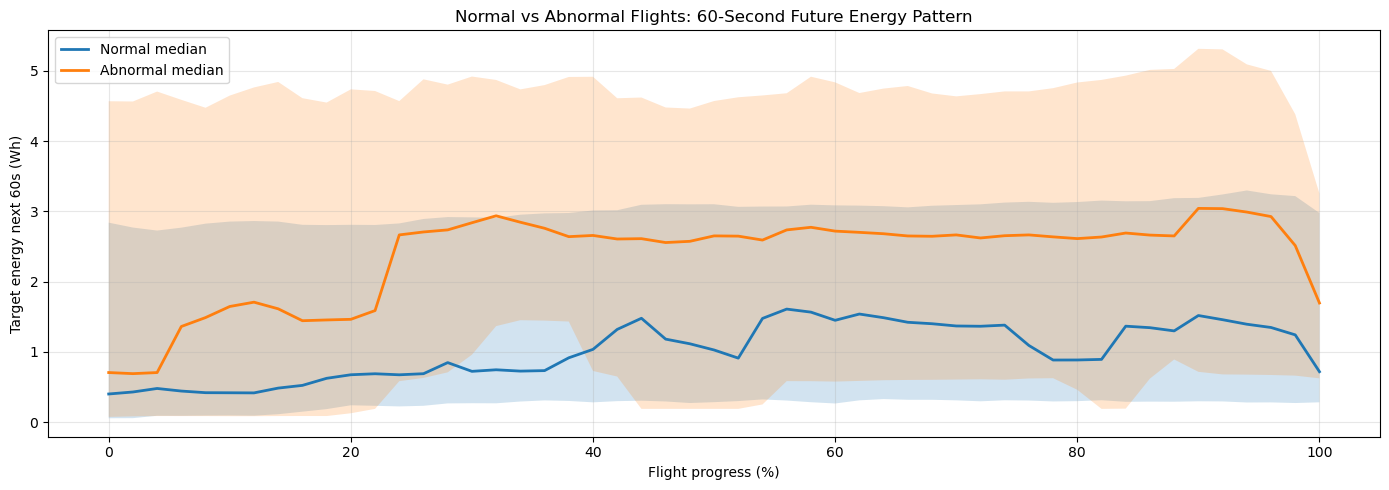

In [42]:
plot_normal_abnormal_profile(
    data=plot_data,
    value_col=target_col,
    y_label="Target energy next 60s (Wh)",
    title="Normal vs Abnormal Flights: 60-Second Future Energy Pattern"
)

Abnormal flights have a higher median target_energy_next_60s_wh than normal flights.

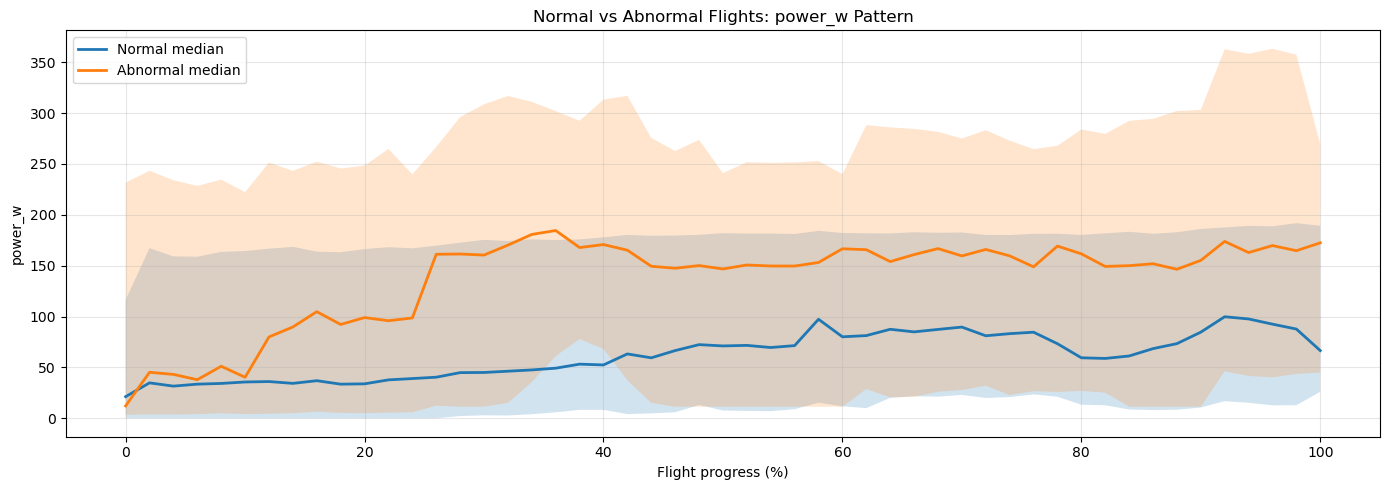

In [43]:
plot_normal_abnormal_profile(
    data=plot_data,
    value_col=highest_corr_feature,
    y_label=highest_corr_feature,
    title=f"Normal vs Abnormal Flights: {highest_corr_feature} Pattern"
)


Abnormal flights also have a higher median power_w than normal flights.

Median was chosen because UAV flight data can have sharp spikes and outliers.

## 21. File saving

In [29]:
train_no_dr_imputed.to_csv(MODEL_READY_DIR / "train_no_dr_imputed.csv", index=False)
val_no_dr_imputed.to_csv(MODEL_READY_DIR / "val_no_dr_imputed.csv", index=False)
test_no_dr_imputed.to_csv(MODEL_READY_DIR / "test_no_dr_imputed.csv", index=False)

train_no_dr_scaled.to_csv(MODEL_READY_DIR / "train_no_dr_scaled.csv", index=False)
val_no_dr_scaled.to_csv(MODEL_READY_DIR / "val_no_dr_scaled.csv", index=False)
test_no_dr_scaled.to_csv(MODEL_READY_DIR / "test_no_dr_scaled.csv", index=False)

joblib.dump(scaler, MODEL_READY_DIR / "standard_scaler_no_dr.joblib")

with open(MODEL_READY_DIR / "final_feature_columns_no_dr.json", "w") as f:
    json.dump(feature_cols_final, f, indent=4)

print("Saved all no-dimensionality-reduction model-ready files to:")
print(MODEL_READY_DIR)

Saved all no-dimensionality-reduction model-ready files to:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr


#For Random Forest / XGBoost:
train_no_dr_imputed.csv
val_no_dr_imputed.csv
test_no_dr_imputed.csv

#For Linear Regression / LSTM / Autoencoder:
train_no_dr_scaled.csv
val_no_dr_scaled.csv
test_no_dr_scaled.csv

Two versions of the dataset were prepared. An imputed but unscaled dataset was retained for Random Forest and XGBoost because tree-based algorithms are generally insensitive to feature scaling. A standardised version of the dataset was also created for Linear Regression, LSTM, Bi-LSTM and Autoencoder models, as these methods typically benefit from inputs being on a similar numerical scale.

Features: ['battery_status__voltage_v', 'battery_status__current_a', 'power_w', 'cumulative_energy_wh', 'target_energy_next_60s_wh']
Normal   : 42b57f46  2391s  23914 rows
Abnormal : 3d552044  1819s  18163 rows


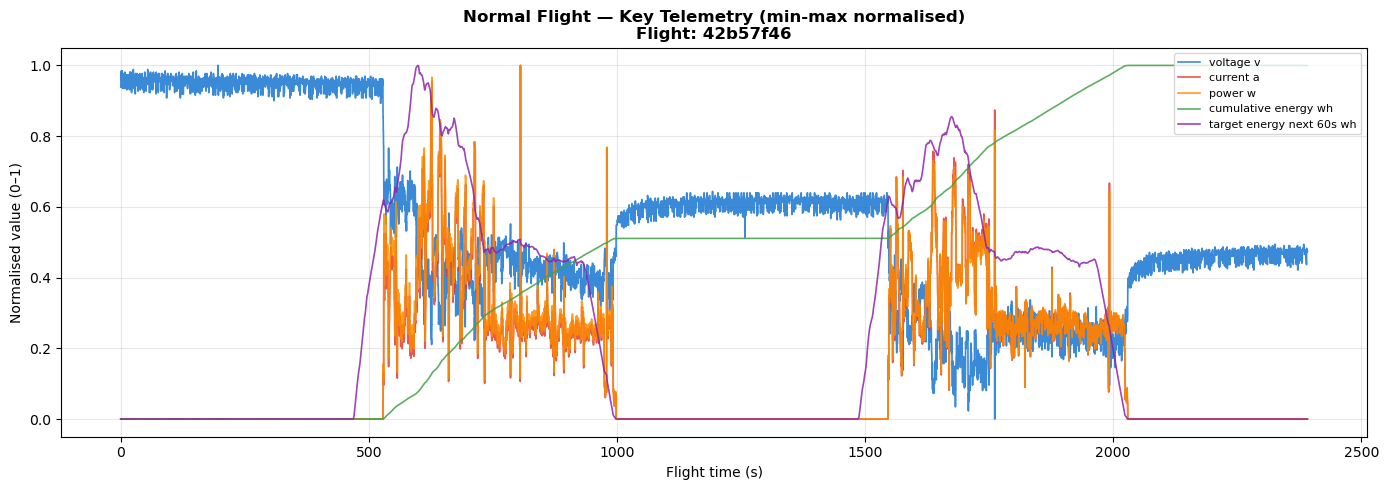

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/plots/timeseries_normal_flight.png


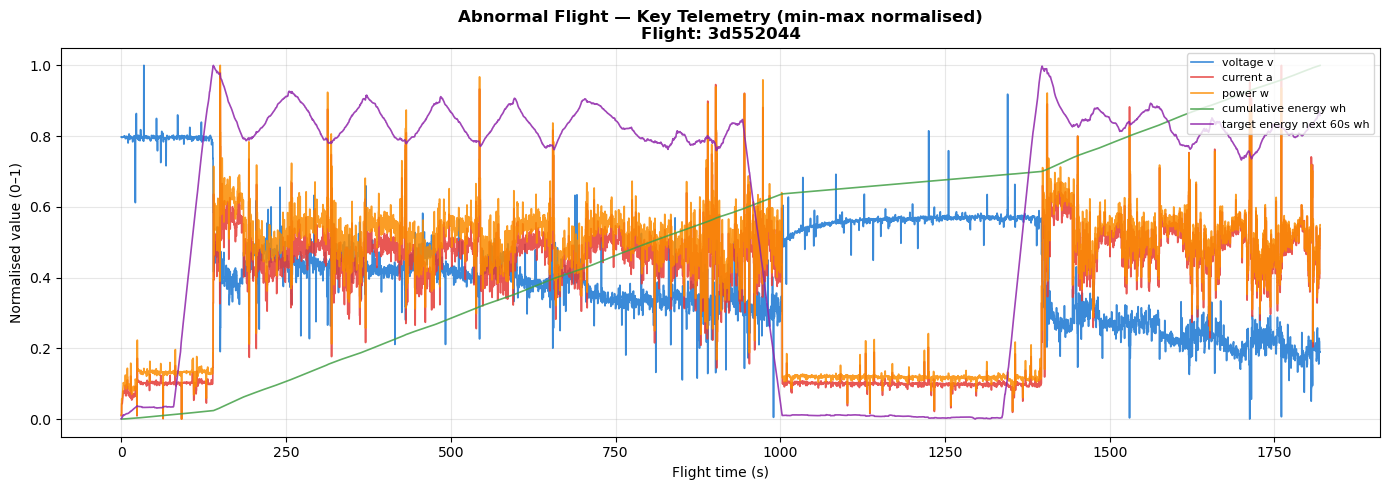

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/plots/timeseries_abnormal_flight.png


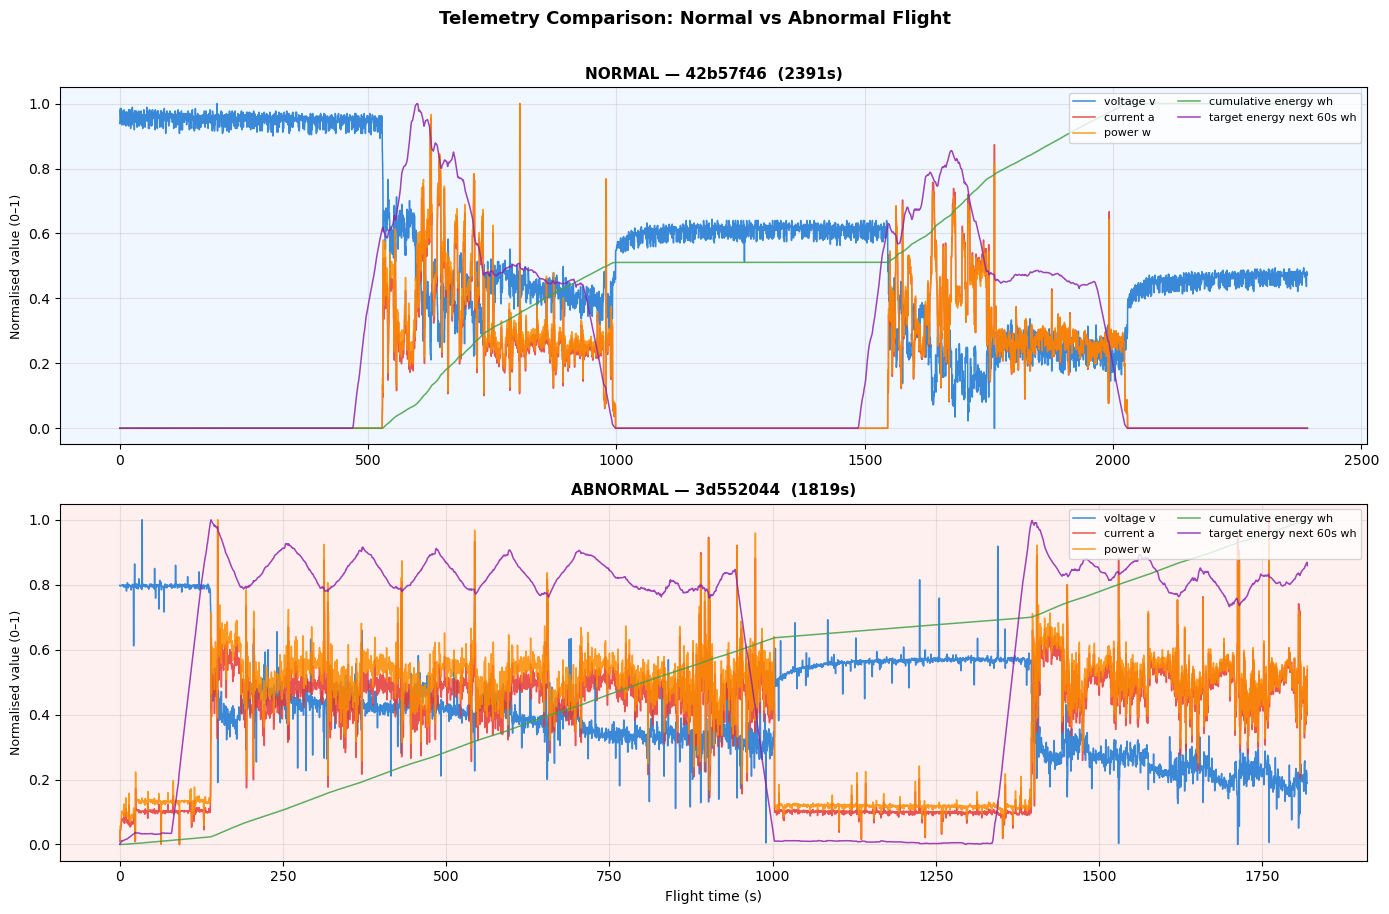

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/plots/timeseries_normal_vs_abnormal_comparison.png


In [14]:


# ── Features available in this notebook ──────────────────────
timeseries_features = [
    "battery_status__voltage_v",
    "battery_status__current_a",
    "power_w",
    "cumulative_energy_wh",
    "target_energy_next_60s_wh"
]
# Use train_no_dr_imputed — that's what exists in notebook 02
_ref = train_no_dr_imputed
timeseries_features = [c for c in timeseries_features if c in _ref.columns]
print("Features:", timeseries_features)

# ── Select representative flights ─────────────────────────────
normal_id = (
    _ref[_ref["dataset_label"] == "normal"]
    .groupby("log_id").size()
    .sort_values(ascending=False)
    .index[0]
)
abnormal_id = (
    _ref[_ref["dataset_label"] == "abnormal"]
    .groupby("log_id").size()
    .sort_values(ascending=False)
    .index[0]
)

normal_plot_df   = _ref[_ref["log_id"] == normal_id].sort_values("time_s").copy()
abnormal_plot_df = _ref[_ref["log_id"] == abnormal_id].sort_values("time_s").copy()

print(f"Normal   : {normal_id[:8]}  {normal_plot_df['time_s'].max():.0f}s  {len(normal_plot_df)} rows")
print(f"Abnormal : {abnormal_id[:8]}  {abnormal_plot_df['time_s'].max():.0f}s  {len(abnormal_plot_df)} rows")

# ── Plot function ─────────────────────────────────────────────
def plot_normalised_timeseries(flight_df, title, save_name):
    """Min-max normalise and plot key telemetry. Normalisation for display only."""
    plot_df = flight_df[["time_s"] + timeseries_features].copy()
    for col in timeseries_features:
        lo, hi = plot_df[col].min(), plot_df[col].max()
        plot_df[col] = (plot_df[col] - lo) / (hi - lo) if hi != lo else 0.0

    colors = ["#1976D2", "#E53935", "#FB8C00", "#43A047", "#8E24AA"]
    fig, ax = plt.subplots(figsize=(14, 5))
    for col, color in zip(timeseries_features, colors):
        ax.plot(plot_df["time_s"], plot_df[col],
                label=col.replace("battery_status__", "").replace("_", " "),
                linewidth=1.2, color=color, alpha=0.85)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Flight time (s)", fontsize=10)
    ax.set_ylabel("Normalised value (0–1)", fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{save_name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {PLOT_DIR / save_name}.png")
    plt.close()

# ── Individual plots ──────────────────────────────────────────
plot_normalised_timeseries(
    normal_plot_df,
    title=f"Normal Flight — Key Telemetry (min-max normalised)\nFlight: {normal_id[:8]}",
    save_name="timeseries_normal_flight"
)

plot_normalised_timeseries(
    abnormal_plot_df,
    title=f"Abnormal Flight — Key Telemetry (min-max normalised)\nFlight: {abnormal_id[:8]}",
    save_name="timeseries_abnormal_flight"
)

# ── Stacked comparison panel (best for report) ────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)
colors = ["#1976D2", "#E53935", "#FB8C00", "#43A047", "#8E24AA"]

for ax, flight_df, label, bg in zip(
    axes,
    [normal_plot_df, abnormal_plot_df],
    ["NORMAL", "ABNORMAL"],
    ["#F0F7FF", "#FFF0F0"]
):
    plot_df = flight_df[["time_s"] + timeseries_features].copy()
    for col in timeseries_features:
        lo, hi = plot_df[col].min(), plot_df[col].max()
        plot_df[col] = (plot_df[col] - lo) / (hi - lo) if hi != lo else 0.0

    ax.set_facecolor(bg)
    for col, color in zip(timeseries_features, colors):
        ax.plot(plot_df["time_s"], plot_df[col],
                label=col.replace("battery_status__", "").replace("_", " "),
                linewidth=1.1, color=color, alpha=0.85)
    ax.set_title(
        f"{label} — {flight_df['log_id'].iloc[0][:8]}  ({flight_df['time_s'].max():.0f}s)",
        fontsize=11, fontweight="bold"
    )
    ax.set_ylabel("Normalised value (0–1)", fontsize=9)
    ax.legend(fontsize=8, loc="upper right", ncol=2)
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel("Flight time (s)", fontsize=10)
fig.suptitle("Telemetry Comparison: Normal vs Abnormal Flight",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / "timeseries_normal_vs_abnormal_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {PLOT_DIR}/timeseries_normal_vs_abnormal_comparison.png")
plt.close()

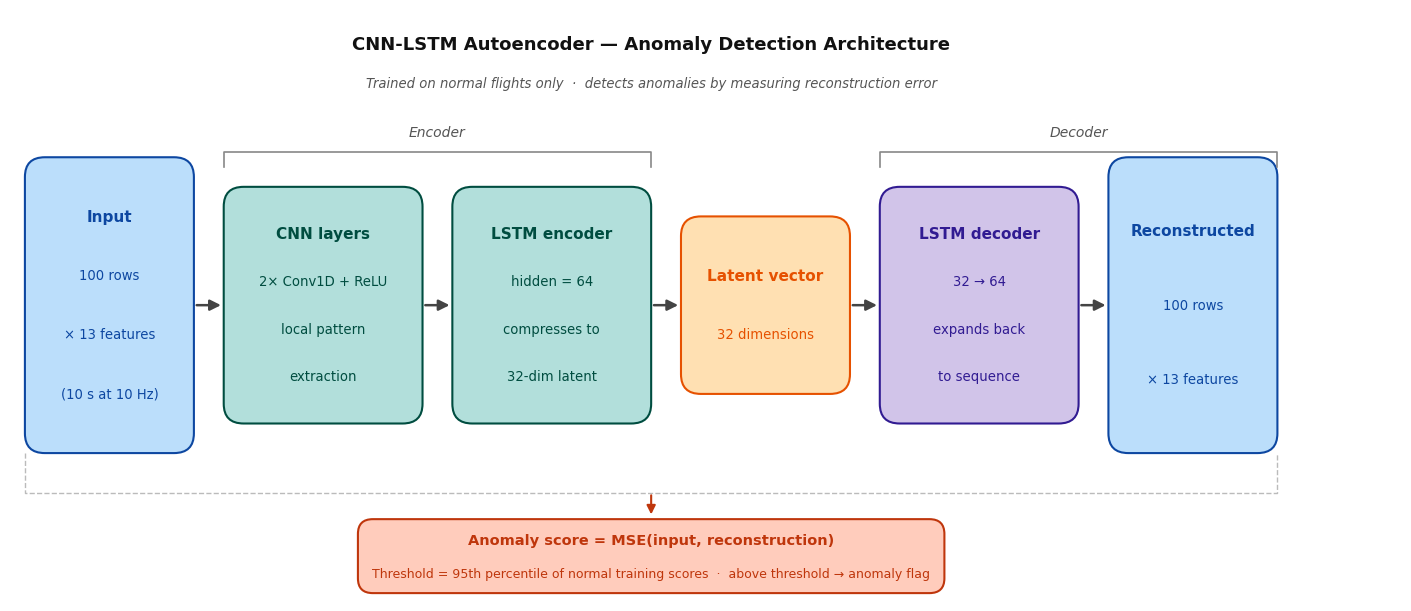

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/eda_outputs/cnn_lstm_ae_architecture.png


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

fig, ax = plt.subplots(figsize=(14, 6))
ax.set_xlim(0, 14)
ax.set_ylim(0, 6)
ax.axis("off")
fig.patch.set_facecolor("white")

BLUE   = ("#BBDEFB", "#0D47A1")
TEAL   = ("#B2DFDB", "#004D40")
AMBER  = ("#FFE0B2", "#E65100")
PURPLE = ("#D1C4E9", "#311B92")
CORAL  = ("#FFCCBC", "#BF360C")

def box(ax, x, y, w, h, lines, colors, bold_first=True):
    fc, tc = colors
    p = mpatches.FancyBboxPatch((x, y), w, h,
        boxstyle="round,pad=0.0,rounding_size=0.2",
        linewidth=1.5, edgecolor=tc, facecolor=fc, zorder=2)
    ax.add_patch(p)
    n = len(lines)
    spacing = h / (n + 1)
    for i, line in enumerate(lines):
        ty = y + h - spacing * (i + 1)
        fw = "bold" if (i == 0 and bold_first) else "normal"
        fs = 11 if (i == 0 and bold_first) else 9.5
        ax.text(x + w/2, ty, line, ha="center", va="center",
                fontsize=fs, fontweight=fw, color=tc, zorder=3)

def arr(ax, x1, x2, y=3.0):
    ax.annotate("", xy=(x2, y), xytext=(x1, y),
                arrowprops=dict(arrowstyle="-|>", color="#444",
                                lw=1.8, mutation_scale=16), zorder=4)

# ── boxes ─────────────────────────────────────────────────────
box(ax, 0.15, 1.5,  1.7, 3.0, ["Input", "100 rows", "× 13 features", "(10 s at 10 Hz)"], BLUE)
box(ax, 2.15, 1.8,  2.0, 2.4, ["CNN layers", "2× Conv1D + ReLU", "local pattern", "extraction"], TEAL)
box(ax, 4.45, 1.8,  2.0, 2.4, ["LSTM encoder", "hidden = 64", "compresses to", "32-dim latent"], TEAL)
box(ax, 6.75, 2.1,  1.7, 1.8, ["Latent vector", "32 dimensions"], AMBER)
box(ax, 8.75, 1.8,  2.0, 2.4, ["LSTM decoder", "32 → 64", "expands back", "to sequence"], PURPLE)
box(ax, 11.05, 1.5, 1.7, 3.0, ["Reconstructed", "100 rows", "× 13 features"], BLUE)

# ── arrows ────────────────────────────────────────────────────
arr(ax, 1.85, 2.15)
arr(ax, 4.15, 4.45)
arr(ax, 6.45, 6.75)
arr(ax, 8.45, 8.75)
arr(ax, 10.75, 11.05)

# ── encoder / decoder brackets ────────────────────────────────
for x1, x2, label in [(2.15, 6.45, "Encoder"), (8.75, 12.75, "Decoder")]:
    ax.plot([x1, x1, x2, x2], [4.4, 4.55, 4.55, 4.4], color="#888", lw=1.2)
    ax.text((x1+x2)/2, 4.68, label, ha="center", va="bottom",
            fontsize=10, color="#555", style="italic")

# ── dashed bracket + anomaly score box ───────────────────────
ax.plot([0.15, 0.15, 12.75, 12.75], [1.5, 1.1, 1.1, 1.5],
        color="#bbb", lw=1, linestyle="--")
ax.annotate("", xy=(6.45, 0.85), xytext=(6.45, 1.1),
            arrowprops=dict(arrowstyle="-|>", color="#BF360C",
                            lw=1.5, mutation_scale=13), zorder=4)

fc, tc = CORAL
p = mpatches.FancyBboxPatch((3.5, 0.08), 5.9, 0.75,
    boxstyle="round,pad=0.0,rounding_size=0.15",
    linewidth=1.5, edgecolor=tc, facecolor=fc, zorder=2)
ax.add_patch(p)
ax.text(6.45, 0.62, "Anomaly score = MSE(input, reconstruction)",
        ha="center", va="center", fontsize=10.5, fontweight="bold", color=tc, zorder=3)
ax.text(6.45, 0.28,
        "Threshold = 95th percentile of normal training scores  ·  above threshold → anomaly flag",
        ha="center", va="center", fontsize=9, color=tc, zorder=3)

# ── title ─────────────────────────────────────────────────────
ax.text(6.45, 5.65, "CNN-LSTM Autoencoder — Anomaly Detection Architecture",
        ha="center", va="center", fontsize=13, fontweight="bold", color="#111")
ax.text(6.45, 5.25,
        "Trained on normal flights only  ·  detects anomalies by measuring reconstruction error",
        ha="center", va="center", fontsize=9.5, color="#555", style="italic")

plt.tight_layout(pad=0.3)

SAVE = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/"
            "uav_px4_dataset_project/eda_outputs/cnn_lstm_ae_architecture.png")
plt.savefig(SAVE, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {SAVE}")
plt.close()